In [1]:
import eu9_osm
import numpy as np
from shapely import transform
import matplotlib.pyplot as plt
from curved_text import curved_text

In [2]:
# Data
lat = 38.71139
lon = -9.1375
roads = eu9_osm.features_from_point((lat, lon), tags={"highway": True}, dist=1000, shape="box")
streets = roads[roads.geometry.geom_type.isin(["LineString", "MultiLineString"])]

In [3]:
# Original streets
original = streets.to_crs("EPSG:3763")

# Distorted streets
def wave(x, y, z=None):
    return x + 100 * np.sin(y / 150), y
    
distorted = original.copy()
distorted["geometry"] = distorted.geometry.apply(lambda g: transform(g, wave, interleaved=False))

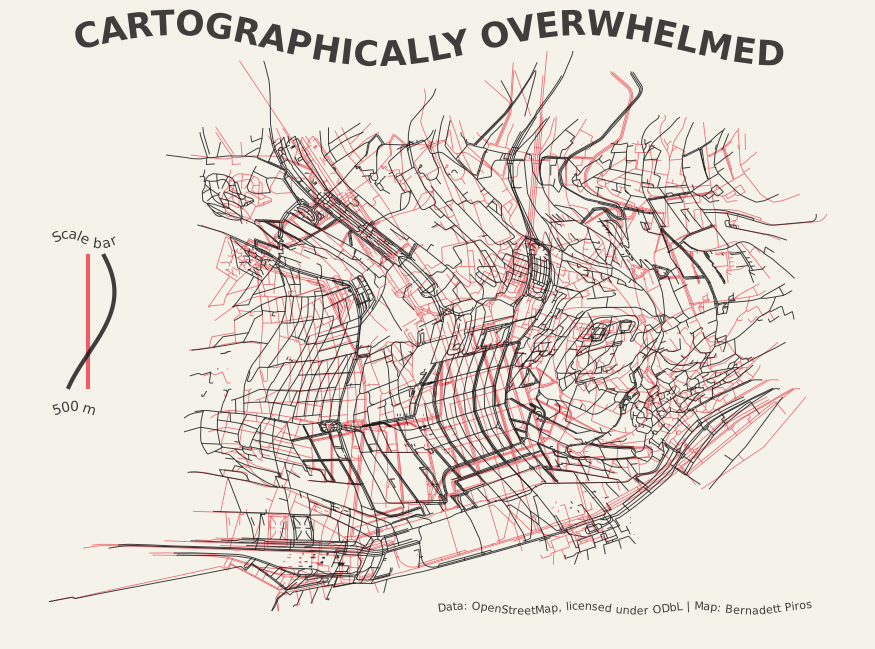

In [4]:
fig, ax = plt.subplots(figsize=(12, 8), facecolor="#F5F2EA")

# Original streets
original.plot(ax=ax, color="#E63946", alpha=0.7, lw=0.6)

# Distorted streets
distorted.plot(ax=ax, color="#111111", alpha=0.8, lw=0.7)

# Scale bar
xmin, ymin, xmax, ymax = original.total_bounds

x0 = xmin + 0.05 * (xmax - xmin)
y0 = ymin + 0.40 * (ymax - ymin)

y = np.linspace(y0, y0 + 500, 200)
x = np.full_like(y, x0)

xd, yd = wave(x, y)

ax.plot(x, y, color="#E63946", alpha=0.8, linewidth=3)
ax.plot(xd, yd, color="#111111", alpha=0.8, linewidth=3)

ax.set_aspect("equal")
ax.set_facecolor("#F5F2EA")
ax.axis("off")

# Curved text 
t = np.linspace(0, 1, 400)
# Text, x, y, width, amplitude, waves, size, weight
labels = [
    ("CARTOGRAPHICALLY OVERWHELMED", 0.075, 0.975, 0.95, 0.025, 2, 25, "bold"),
    ("500 m", 0.05, 0.37,  0.10, 0.008, 1, 10, "normal"),
    ("Scale bar", 0.05, 0.65,  0.15, 0.008, 2, 10, "normal"),
    ("Data: OpenStreetMap, licensed under ODbL | Map: Bernadett Piros", 0.5,  0.05,  0.40, 0.004, 3,  8, "normal")
]

for text, x0, y0, width, amplitude, waves, size, weight in labels:
    # Invisible sine wave
    x = x0 + width * t
    y = y0 + amplitude * np.sin(2 * np.pi * waves * t)
    # Conbines the 2 arrays
    points = np.column_stack([x, y])
    # Convert axes coords to data coords 
    x, y = ax.transData.inverted().transform(ax.transAxes.transform(points)).T

    curved_text(ax, x, y, text, pos=0, anchor="start", offset=0, color="#111111",
                alpha=0.8, size=size, weight=weight, clip_on=False)

#plt.show()

fig.savefig("feeling.png", bbox_inches="tight", pad_inches=0.2)